# Chapitre 7 · pandas et analyse de données

Trois études de cas fictives : analyser des commandes, comparer des délais et prévoir une consommation. Les exercices suivent les diapositives. Écrire les étapes, essayer, puis lire la correction.

## Préparation
Bibliothèques : pandas, NumPy, SciPy, Seaborn et Matplotlib. Si nécessaire : `python -m pip install pandas numpy scipy seaborn matplotlib jupyter` dans le terminal. Les fichiers CSV sont embarqués ci-dessous et copiés dans un dossier temporaire. Les sources brutes restent disponibles dans le pack.

In [1]:
%matplotlib inline
from pathlib import Path
from tempfile import TemporaryDirectory
import pandas as pd
import numpy as np
from scipy import stats, linalg
import scipy, seaborn as sns, matplotlib.pyplot as plt
import matplotlib
espace = TemporaryDirectory(prefix="chapitre07_")
donnees = Path(espace.name) / "donnees"
sorties = Path(espace.name) / "sorties"
donnees.mkdir(); sorties.mkdir()
fichiers_csv = {'energie_ch07.csv': 'date;temperature_prevue;heures_prevues;conso_kwh\n2026-09-01;13.23;9.0;126.96\n2026-09-02;18.41;9.0;114.03\n2026-09-03;19.65;9.0;107.99\n2026-09-04;19.39;9.0;111.3\n2026-09-05;16.25;4.0;92.07\n2026-09-06;10.53;4.0;108.54\n2026-09-07;9.12;9.0;138.7\n2026-09-08;7.43;9.0;141.91\n2026-09-09;9.34;9.0;138.56\n2026-09-10;14.88;9.0;112.73\n2026-09-11;16.81;9.0;113.28\n2026-09-12;18.82;4.0;81.85\n2026-09-13;18.54;4.0;81.48\n2026-09-14;16.9;9.0;116.31\n2026-09-15;12.45;9.0;130.71\n2026-09-16;8.61;9.0;142.54\n2026-09-17;9.39;9.0;134.35\n2026-09-18;9.76;9.0;137.18\n2026-09-19;12.95;4.0;96.31\n2026-09-20;18.49;4.0;83.28\n2026-09-21;20.1;9.0;104.11\n2026-09-22;19.32;9.0;106.54\n2026-09-23;15.05;9.0;119.11\n2026-09-24;12.1;9.0;131.25\n2026-09-25;8.89;9.0;132.83\n2026-09-26;7.27;4.0;118.7\n2026-09-27;10.75;4.0;105.69\n2026-09-28;14.5;9.0;120.86\n2026-09-29;19.09;9.0;111.98\n2026-09-30;19.68;9.0;109.7\n2026-10-01;19.2;9.0;107.93\n2026-10-02;16.37;9.0;122.97\n2026-10-03;10.75;4.0;107.97\n2026-10-04;8.26;4.0;116.38\n2026-10-05;7.48;9.0;145.76\n2026-10-06;10.06;9.0;133.33\n2026-10-07;15.35;9.0;117.9\n2026-10-08;18.66;9.0;111.65\n2026-10-09;20.26;9.0;99.69\n2026-10-10;19.19;4.0;80.64\n', 'clients_ch07.csv': 'client;ville\nC1;Lyon\nC2;Nantes\nC3;Lille\nC4;Lyon\nC5;Nantes\nC6;Lille\n', 'commandes_ch07.csv': 'id;date;client;produit;quantite;remise_pct\n101;2026-09-01;C1;P1;1;10\n102;2026-09-01;C2;P2;2;\n103;2026-09-02;C3;P3;3;\n104;2026-09-02;C4;P1;4;\n105;2026-09-03;C5;P2;1;\n106;2026-09-03;C6;P3;2;10\n107;2026-09-04;C1;P1;3;\n108;2026-09-04;C2;P2;4;\n109;2026-09-05;C3;P3;1;\n110;2026-09-05;C4;P1;2;\n111;2026-09-07;C5;P2;3;10\n112;2026-09-07;C6;P3;4;\n113;2026-09-08;C1;P1;1;\n114;2026-09-08;C2;P2;2;\n115;2026-09-09;C3;P3;3;\n116;2026-09-09;C4;P1;4;10\n117;2026-09-10;C5;P2;1;\n118;2026-09-10;C6;P3;2;\n119;2026-09-11;C1;P1;3;\n120;2026-09-11;C2;P2;4;\n121;2026-09-12;C3;P3;1;10\n122;2026-09-12;C4;P1;2;\n104;2026-09-02;C4;P1;4;\n123;2026-09-07;C1;P1;?;\n124;inconnue;C2;P2;2;\n125;2026-09-12;C3;PX;1;\n', 'livraisons_ch07.csv': 'client;methode;delai\nT00;A;30.0\nT01;A;32.0\nT02;A;28.0\nT03;A;35.0\nT04;A;31.0\nT05;A;29.0\nT06;A;33.0\nT07;A;34.0\nT08;A;27.0\nT09;A;36.0\nT10;A;32.0\nT11;A;31.0\nT12;A;30.0\nT13;A;34.0\nT14;A;29.0\nT15;A;33.0\nT16;A;35.0\nT17;A;28.0\nT18;A;32.0\nT19;A;31.0\nT20;B;26.0\nT21;B;29.0\nT22;B;25.0\nT23;B;31.0\nT24;B;28.0\nT25;B;24.0\nT26;B;30.0\nT27;B;27.0\nT28;B;26.0\nT29;B;32.0\nT30;B;29.0\nT31;B;28.0\nT32;B;25.0\nT33;B;30.0\nT34;B;27.0\nT35;B;26.0\nT36;B;31.0\nT37;B;24.0\nT38;B;28.0\nT39;B;27.0\n', 'produits_ch07.csv': 'produit;libelle;prix;cout\nP1;Cahier;10.0;6.0\nP2;Gourde;15.0;9.0\nP3;Lampe;25.0;16.0\n'}
for nom, contenu in fichiers_csv.items():
    (donnees / nom).write_text(contenu, encoding="utf-8")
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.figsize": (7.6,4.2), "figure.dpi": 120,
    "axes.spines.top":False, "axes.spines.right":False, "grid.alpha":.25})
print("pandas",pd.__version__,"NumPy",np.__version__,"SciPy",scipy.__version__,"Seaborn",sns.__version__)

print("Dossier des données :", donnees)
print("Dossier des exports pendant cette session :", sorties)

pandas 3.0.6 NumPy 2.5.4 SciPy 1.18.1 Seaborn 0.13.2
Dossier des données : /var/folders/22/zwnd79yn6mqdc_bjrmp_mdj80000gn/T/chapitre07_556hbjgo/donnees
Dossier des exports pendant cette session : /var/folders/22/zwnd79yn6mqdc_bjrmp_mdj80000gn/T/chapitre07_556hbjgo/sorties


## 2. Trois questions qui donnent un but à l’analyse

Une boutique veut savoir quels produits contribuent le plus à son chiffre d'affaires. Elle possède des exports imparfaits.



Un service compare deux méthodes de livraison. Une différence de moyenne suffit-elle pour conclure ?



Un bâtiment veut prévoir sa consommation du lendemain. Quelles informations sont disponibles au moment de prévoir ?

## 3. Du fichier à une conclusion vérifiable

Fichiers bruts → données contrôlées → calculs → conclusion.



Une analyse exploratoire cherche des régularités, des erreurs et des questions à approfondir.
Chaque résultat doit préciser la population, la période et l'unité.



Le notebook conserve les essais et les corrections. Les données fournies sont entièrement fictives.

## 4. Les fichiers : une ligne représente quoi ?

Fichier | Une ligne | Clé
--- | --- | ---
Commandes | Une commande d’un seul produit | id
Produits | Un produit et son prix | produit
Clients | Un client et sa ville | client


Les commandes couvrent les 12 premiers jours de septembre 2026. L'export est complet. Le 6 septembre, aucune commande n'a eu lieu.



Une **clé** identifie une ligne dans sa table. Une colonne de référence relie une commande à son produit ou à son client.

## 5. Les quantités que l’on veut calculer

Pour une commande :
$$
\text{brut}=\text{quantité}\times\text{prix},\qquad
\text{net}=\text{brut}\left(1-\frac{\text{remise}}{100}\right).
$$
Le chiffre d'affaires est la somme des montants nets, en euros.



Le panier moyen est le chiffre d'affaires divisé par le nombre de commandes retenues.



La marge brute est le montant net moins le coût des articles. Elle ne comprend pas ici le loyer, les salaires ni les autres charges.

## 6. Un rôle pour chaque bibliothèque

Bibliothèque | Rôle dans le chapitre
--- | ---
pandas | Lire, relier, nettoyer et résumer les tables
NumPy | Calculer sur les colonnes et former des matrices
SciPy | Comparer des moyennes et ajuster un modèle
Seaborn / Matplotlib | Construire puis annoter les graphiques


Seaborn propose des graphiques à partir des noms de colonnes.
Matplotlib permet d'ajuster les axes, les titres et les légendes.

## 7. Lire un fichier sans deviner son contenu

`read_csv` lit une table. `sep=";"` indique le séparateur du fichier. `dtype="string"` conserve d'abord les champs sous forme de texte.



`donnees` est le dossier fourni, défini dans le notebook.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats, linalg
import seaborn as sns
import matplotlib.pyplot as plt
commandes = pd.read_csv(donnees / "commandes_ch07.csv",
                        sep=";", dtype="string")
produits = pd.read_csv(donnees / "produits_ch07.csv", sep=";")
clients = pd.read_csv(donnees / "clients_ch07.csv", sep=";")

## 8. Un premier contrôle avant les statistiques

`shape` compte les lignes et colonnes. `info()` affiche leurs types et leurs valeurs présentes. `isna()` repère les valeurs absentes.



Une moyenne de texte converti trop vite peut cacher une erreur de fichier.

In [3]:
print(commandes.shape)
print(commandes.head(4))
commandes.info()
print(commandes.isna().sum())

(26, 6)
    id        date client produit quantite remise_pct
0  101  2026-09-01     C1      P1        1         10
1  102  2026-09-01     C2      P2        2       <NA>
2  103  2026-09-02     C3      P3        3       <NA>
3  104  2026-09-02     C4      P1        4       <NA>
<class 'pandas.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          26 non-null     string
 1   date        26 non-null     string
 2   client      26 non-null     string
 3   produit     26 non-null     string
 4   quantite    26 non-null     string
 5   remise_pct  5 non-null      string
dtypes: string(6)
memory usage: 1.3 KB
id             0
date           0
client         0
produit        0
quantite       0
remise_pct    21
dtype: int64


## 9. Convertir le texte et garder la trace des échecs

`str.strip()` retire les espaces au début et à la fin du texte.
`to_numeric` convertit les nombres. `to_datetime` convertit les dates.



Avec `errors="coerce"`, un échec devient absent : `NaN` pour un nombre, `NaT` pour une date. Il faut ensuite le compter.

In [4]:
travail = commandes.copy()
travail["date"] = pd.to_datetime(travail["date"],
    format="%Y-%m-%d", errors="coerce")
travail["quantite"] = pd.to_numeric(
    travail["quantite"].str.strip(), errors="coerce")

## 10. Exercice : séparer les commandes à vérifier

Les commandes 123 et 124 ont respectivement une quantité illisible et une date illisible.



- Écrire les étapes pour repérer une date absente, une quantité absente ou une quantité non positive.

- Construire un masque avec `isna()`, `|` et `<=`.

- Conserver les lignes douteuses dans `rejets`, puis copier les autres dans `valides`.


`|` signifie « ou » case par case. `~` inverse un masque. Chaque comparaison est entre parenthèses.

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [5]:
# Votre essai

## 11. Correction : les rejets restent consultables

On conserve 24 lignes à ce stade. Une répétition et une référence produit inconnue restent à traiter.

In [6]:
invalide = (travail["date"].isna()
            | travail["quantite"].isna()
            | (travail["quantite"] <= 0))
rejets = travail.loc[invalide].copy()
valides = travail.loc[~invalide].copy()
print(rejets["id"].tolist(), len(valides))

['123', '124'] 24


## 12. Un doublon peut gonfler le chiffre d’affaires

La commande 104 figure deux fois, avec les mêmes informations. Le fournisseur confirme une répétition d'export.



`duplicated(subset=...)` repère une clé répétée. `drop_duplicates` garde ici la première occurrence.



Deux lignes avec la même clé et des montants différents demanderaient une enquête. La règle ci-dessous dépend de la répétition exacte confirmée.

In [7]:
print(valides.loc[valides.duplicated("id", keep=False), "id"])
valides = valides.drop_duplicates(subset="id").copy()
assert valides["id"].is_unique

3     104
22    104
Name: id, dtype: string


## 13. Une valeur absente demande une règle explicite

Dans cet export, une remise vide signifie « aucune remise ». Cette règle vient de la définition du fichier.



`fillna(0)` est donc justifié pour cette colonne. Un prix inconnu ou une quantité illisible ne recevraient pas automatiquement zéro.



`between(0, 100)` teste que chaque remise appartient à cet intervalle, bornes incluses.

In [8]:
valides["remise_pct"] = pd.to_numeric(
    valides["remise_pct"], errors="raise").fillna(0)
assert valides["remise_pct"].between(0, 100).all()

## 14. Relier une commande à son produit

Commande | produit
--- | ---
101 | P1
102 | P2
125 | PX





produit | prix
--- | ---
P1 | 10 euros
P2 | 15 euros
P3 | 25 euros


La jointure cherche le même code dans les deux tables. PX n'a aucune correspondance.
Une jointure à gauche garde toutes les commandes pour rendre ce manque visible.

## 15. merge : la clé, le sens et la cardinalité

`on` désigne la clé. `how="left"` garde les lignes de gauche.
`validate="many_to_one"` exige au plus une correspondance à droite.



`indicator=True` ajoute `_merge` : `both` indique une correspondance et `left_only` une référence inconnue.

In [9]:
jointes = valides.merge(produits, on="produit", how="left",
                        validate="many_to_one", indicator=True)
print(jointes["_merge"].value_counts())

_merge
both          22
left_only      1
right_only     0
Name: count, dtype: int64


## 16. Débogage : deux prix pour le même code

Un fichier erroné contient deux lignes P1. Une jointure sans contrôle répéterait chaque commande de P1.



- Dessiner le résultat pour une commande de 2 cahiers et deux lignes P1.

- Expliquer pourquoi la somme des ventes pourrait doubler pour ces commandes.

- Quel contrôle doit provoquer une erreur ? Que faut-il faire de PX ?


Le nombre de lignes avant et après une jointure est un contrôle utile.

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [10]:
# Votre essai

## 17. Correction : 22 commandes avec un prix connu

`drop(columns=...)` retire une colonne. On garde PX dans une table de contrôle. La seconde jointure ajoute la ville sans créer de commandes supplémentaires.

In [11]:
sans_prix = jointes.loc[jointes["_merge"] == "left_only"].copy()
ventes = jointes.loc[jointes["_merge"] == "both"].drop(
    columns="_merge").copy()
ventes = ventes.merge(clients, on="client", how="left",
                      validate="many_to_one")
assert len(ventes) == 22 and ventes["id"].is_unique
assert ventes["ville"].notna().all()

## 18. Des calculs de colonnes avec pandas et NumPy

Les opérations entre colonnes s'appliquent ligne par ligne.
`np.where(condition, a, b)` choisit entre deux valeurs pour chaque ligne.



Ici, « gros panier » signifie au moins 50 euros nets. C'est une règle d'analyse choisie, pas une propriété de pandas.

In [12]:
ventes["brut"] = ventes["quantite"] * ventes["prix"]
ventes["net"] = ventes["brut"] * (1 - ventes["remise_pct"] / 100)
ventes["marge"] = ventes["net"] - ventes["quantite"] * ventes["cout"]
ventes["panier"] = np.where(ventes["net"] >= 50, "gros", "autre")

## 19. Exercice : un résultat et son périmètre

- Vérifier la première commande à la main : 1 cahier à 10 euros, avec 10 % de remise.

- Calculer le chiffre d'affaires, la marge brute totale et le panier moyen des commandes retenues.

- Indiquer combien de lignes brutes ne contribuent pas à ces totaux et pourquoi.


Une somme sans son périmètre peut répondre à la mauvaise question.

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [13]:
# Votre essai

## 20. Correction : des totaux que l’on peut réconcilier

Les résultats portent sur 22 commandes valorisables, sur 26 lignes d'export. Une répétition n'est pas une vente perdue.



Le produit inconnu pourrait ajouter du chiffre d'affaires après résolution. Le total disponible n'est donc pas présenté comme celui de toutes les commandes brutes.

 Résultats : CA net 838 euros, marge brute 309 euros, panier moyen 38,09 euros.

In [14]:
ca = ventes["net"].sum()
marge = ventes["marge"].sum()
panier_moyen = ventes["net"].mean()
print(round(ca, 2), round(marge, 2), round(panier_moyen, 2))

838.0 309.0 38.09


## 21. Plusieurs résumés dans un groupby

`agg` calcule une ligne de résumé par groupe.
`as_index=False` conserve la ville dans une colonne.
Dans `ca=("net", "sum")`, `ca` nomme la sortie, `net` la colonne source et `sum` le calcul.



`size` compte les lignes. `count` compterait seulement les valeurs présentes d'une colonne.

In [15]:
par_ville = ventes.groupby("ville", as_index=False).agg(
    commandes=("id", "size"), ca=("net", "sum"),
    marge=("marge", "sum"), panier_moyen=("net", "mean"))
print(par_ville.round(2))

    ville  commandes     ca  marge  panier_moyen
0   Lille          7  392.5  136.5         56.07
1    Lyon          8  195.0   75.0         24.38
2  Nantes          7  250.5   97.5         35.79


## 22. Résultat : chaque résumé garde son effectif

Ville | Commandes | CA net (euros) | Panier moyen (euros)
--- | --- | --- | ---
Lille | 7 | 392.50 | 56.07
Lyon | 8 | 195.00 | 24.38
Nantes | 7 | 250.50 | 35.79




 La somme des trois chiffres d’affaires vaut 838 euros. La moyenne globale doit pondérer les paniers moyens par les nombres de commandes.

## 23. transform garde une valeur par commande

`agg` réduit chaque groupe à un résumé.
`transform` reporte une statistique du groupe sur chacune de ses lignes.



Pour les paniers 10 et 30 euros d'une même ville, la moyenne de groupe vaut 20 sur les deux lignes. Leurs écarts valent -10 et +10 euros.

In [16]:
ventes["moyenne_ville"] = ventes.groupby("ville")["net"].transform("mean")
ventes["ecart_ville"] = ventes["net"] - ventes["moyenne_ville"]

## 24. Exercice : comparer une commande à sa ville

- Écrire les étapes pour garder les commandes au-dessus de la moyenne de leur ville.

- Utiliser un masque puis `loc` pour montrer id, ville, net et moyenne de ville.

- Trier le résultat par écart décroissant avec `sort_values`.


Une commande peut être au-dessus de la moyenne locale sans être la plus grande de toute la boutique.

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [17]:
# Votre essai

## 25. Correction : le groupe reste visible

La moyenne locale n'est pas un seuil de fraude. Elle sert seulement à comparer des observations du même groupe.

In [18]:
au_dessus = ventes.loc[ventes["net"] > ventes["moyenne_ville"],
    ["id", "ville", "net", "moyenne_ville", "ecart_ville"]]
au_dessus = au_dessus.sort_values("ecart_ville", ascending=False)
print(au_dessus.head(5).round(2))

     id   ville    net  moyenne_ville  ecart_ville
11  112   Lille  100.0          56.07        43.93
7   108  Nantes   60.0          35.79        24.21
19  120  Nantes   60.0          35.79        24.21
2   103   Lille   75.0          56.07        18.93
14  115   Lille   75.0          56.07        18.93


## 26. Un tableau croisé pour deux catégories

`pivot_table` place une catégorie sur les lignes et une autre sur les colonnes.
`aggfunc="sum"` additionne les ventes de chaque combinaison.



Une case vide signifie ici aucune commande valorisable pour cette combinaison. `fill_value=0` remplace cette absence de combinaison par zéro.

In [19]:
croise = ventes.pivot_table(index="ville", columns="libelle",
    values="net", aggfunc="sum", fill_value=0)
print(croise.round(2))

libelle  Cahier  Gourde  Lampe
ville                         
Lille       0.0     0.0  392.5
Lyon      195.0     0.0    0.0
Nantes      0.0   250.5    0.0


## 27. Format long et format large

date | cahiers | lampes
--- | --- | ---
01/09 | 10 | 25
02/09 | 20 | 50





**Format long (extrait)**

date | produit | montant
--- | --- | ---
01/09 | cahiers | 10
01/09 | lampes | 25


Le format large garde une colonne par produit. Le format long garde une colonne pour le produit et une pour le montant.



`melt(id_vars=..., var_name=..., value_name=...)` transforme des colonnes en lignes. Les colonnes `id_vars` restent identifiantes.

In [20]:
large = pd.DataFrame({"date": ["01/09", "02/09"],
                      "cahiers": [10, 20], "lampes": [25, 50]})
long = large.melt(id_vars="date", var_name="produit", value_name="montant")
print(long)

    date  produit  montant
0  01/09  cahiers       10
1  02/09  cahiers       20
2  01/09   lampes       25
3  02/09   lampes       50


## 28. concat empile, merge rapproche des clés

Deux exports de même structure peuvent former une seule table avec `concat`.
`ignore_index=True` attribue de nouveaux numéros de ligne.



Une jointure `merge` ajoute des informations en recherchant des clés correspondantes.



Après un empilement, vérifier les clés répétées. Réinitialiser l'index ne supprime aucun doublon de commande.

In [21]:
lot_a = ventes.iloc[:11].copy()
lot_b = ventes.iloc[11:].copy()
reunies = pd.concat([lot_a, lot_b], ignore_index=True)
assert reunies["id"].is_unique and len(reunies) == 22

## 29. Le graphique dépend de la question

Question | Graphique
--- | ---
Comparer des montants par catégorie | Barres partant de zéro
Voir la distribution des paniers | Histogramme ou boîte
Suivre un montant dans le temps | Courbe avec dates ordonnées
Relier deux mesures | Nuage de points
Lire une table croisée | Carte de chaleur


Un histogramme compte les observations dans des intervalles. Une boîte résume médiane et quartiles. Le notebook montre aussi les points individuels pour garder les petits effectifs visibles.

La médiane est le quantile à 50 %. La boîte couvre les quantiles à 25 % et 75 %.

## 30. Seaborn utilise les noms des colonnes

`data` désigne la table. `x` et `y` nomment les colonnes.
`bins` fixe les bornes des classes. Chaque barre de cet histogramme compte des commandes.

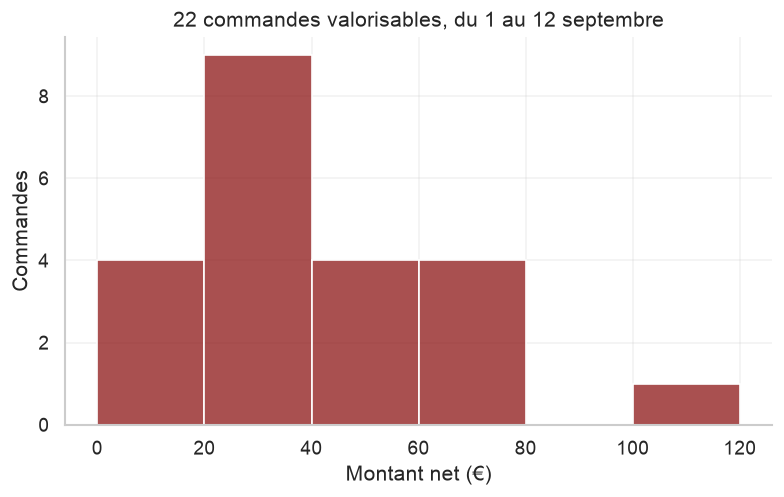

In [22]:
fig, ax = plt.subplots()
sns.histplot(data=ventes, x="net", bins=[0, 20, 40, 60, 80, 100, 120],
             color="#8C1515", ax=ax)
ax.set(xlabel="Montant net (€)", ylabel="Commandes",
       title="22 commandes valorisables, du 1 au 12 septembre")
plt.show()

## 31. Comparer des villes en gardant les effectifs

La hauteur décrit le montant total des commandes retenues. Elle dépend du nombre de commandes et de leur montant.
Comparer les seules hauteurs ne sépare pas ces deux effets.

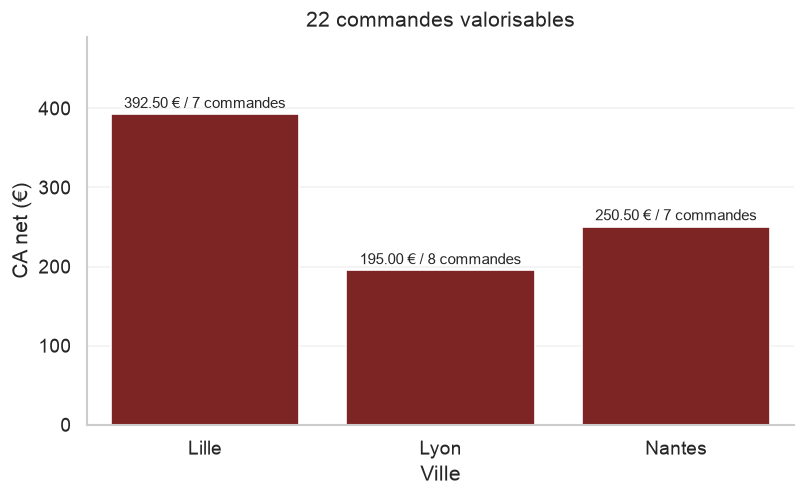

In [23]:
fig, ax = plt.subplots()
sns.barplot(data=par_ville, x="ville", y="ca", color="#8C1515", errorbar=None, ax=ax)
ax.set(title="22 commandes valorisables", xlabel="Ville", ylabel="CA net (€)")
for i, ligne in par_ville.iterrows():
    ax.text(i, ligne["ca"] + 8,
            f'{ligne["ca"]:.2f} € / {ligne["commandes"]} commandes',
            ha="center", fontsize=9)
ax.set_ylim(0, par_ville["ca"].max()*1.25)
plt.show()

## 32. Les dates deviennent un axe de calcul

`dt` donne accès aux composantes d'une colonne de dates, par exemple `dt.dayofweek` : lundi vaut 0.



`set_index("date")` utilise les dates comme étiquettes de ligne. `sort_index()` les remet dans l'ordre.



Plusieurs commandes peuvent avoir la même date. Le prochain calcul les regroupera par jour.

In [24]:
ventes["jour_semaine"] = ventes["date"].dt.dayofweek
chronologie = ventes.set_index("date").sort_index()
print(chronologie.loc["2026-09-01":"2026-09-03", ["id", "net"]])

             id   net
date                 
2026-09-01  101   9.0
2026-09-01  102  30.0
2026-09-02  103  75.0
2026-09-02  104  40.0
2026-09-03  105  15.0
2026-09-03  106  45.0


## 33. resample fabrique des groupes de temps

`resample("D")` regroupe par jour civil. `sum(min_count=1)` demande au moins une valeur présente pour produire une somme.



Le 6 septembre n'a aucune commande. L'export est complet : on peut ici interpréter ce jour comme zéro vente.



Avec un export incomplet, ce zéro serait une hypothèse injustifiée.

In [25]:
journalier = chronologie["net"].resample("D").sum(min_count=1)
journalier = journalier.fillna(0)
print(journalier.round(2))

date
2026-09-01     39.0
2026-09-02    115.0
2026-09-03     60.0
2026-09-04     90.0
2026-09-05     45.0
2026-09-06      0.0
2026-09-07    140.5
2026-09-08     40.0
2026-09-09    111.0
2026-09-10     65.0
2026-09-11     90.0
2026-09-12     42.5
Freq: D, Name: net, dtype: Float64


## 34. Une fenêtre passée pour éviter de lire le futur

`rolling(3)` regroupe trois lignes consécutives. `min_periods=3` exige trois valeurs.



Pour prévoir le jour $t$, les ventes du jour $t$ ne sont pas encore connues. `shift(1)` décale donc les valeurs d'une ligne.



Jour prévu | Jours utilisables
--- | ---
4 septembre | 1, 2 et 3 septembre
5 septembre | 2, 3 et 4 septembre

## 35. Exercice : une moyenne disponible la veille

- Écrire les étapes pour calculer, à chaque date, la moyenne des trois jours précédents.

- Prévoir les trois premières valeurs de sortie.

- Appliquer d'abord `shift(1)`, puis `rolling(3, min_periods=3).mean()`.

- Expliquer pourquoi une fenêtre centrée utiliserait des données futures.

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [26]:
# Votre essai

## 36. Correction : le passé accompagne la courbe



In [27]:
moyenne_passee = journalier.shift(1).rolling(
    3, min_periods=3).mean()
print(moyenne_passee.head(5).round(2))

date
2026-09-01      NaN
2026-09-02      NaN
2026-09-03      NaN
2026-09-04    71.33
2026-09-05    88.33
Freq: D, Name: net, dtype: float64


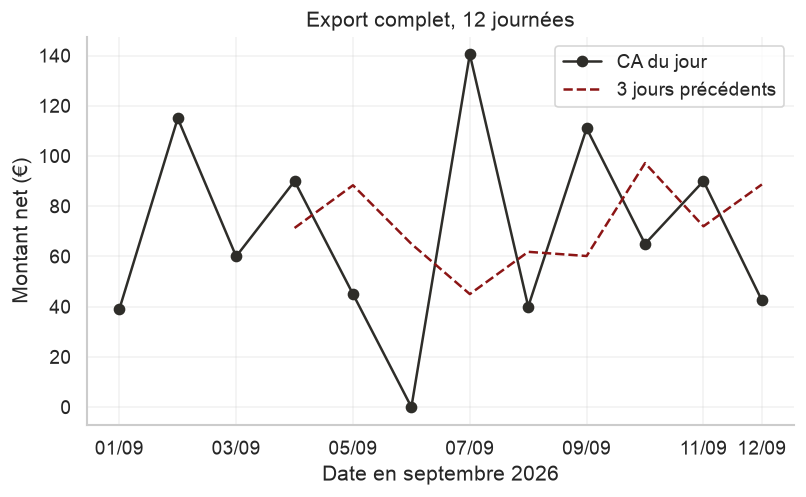

In [28]:
fig, ax = plt.subplots()
ax.plot(journalier.index, journalier, marker="o", label="CA du jour", color="#2E2D29")
ax.plot(journalier.index, moyenne_passee, ls="--", label="3 jours précédents", color="#8C1515")
ax.set_xticks(journalier.index[[0,2,4,6,8,10,11]], journalier.index[[0,2,4,6,8,10,11]].strftime("%d/%m"))
ax.set(xlabel="Date en septembre 2026",ylabel="Montant net (€)",title="Export complet, 12 journées")
ax.legend(); plt.show()

## 37. Un pourcentage global garde son dénominateur

Deux commandes brutes : 10 euros avec 0 % de remise et 100 euros avec 10 %.



La moyenne des pourcentages vaut 5 %. Pourtant, 10 euros de remise sur 110 euros bruts représentent environ 9,09 %.
$$
\text{taux global}=\frac{\sum(\text{brut}-\text{net})}{\sum\text{brut}}.
$$
On additionne d'abord les montants, puis on divise.

In [29]:
taux_remise = (ventes["brut"] - ventes["net"]).sum() / ventes["brut"].sum()
print(round(100 * taux_remise, 2))  # 1.99 %

1.99


## 38. Deux méthodes de livraison : que compare-t-on ?

Quarante clients distincts reçoivent chacun une livraison. Dans ce scénario fictif, on attribue au hasard la méthode A ou B, avec 20 clients par méthode.



Une ligne est une livraison indépendante. `delai` est une durée en minutes.



On cherche la différence **moyenne A moins moyenne B**. Une différence positive indique ici que B est plus rapide en moyenne.

`to_numpy()` extrait les valeurs de la colonne dans un tableau NumPy.

In [30]:
livraisons = pd.read_csv(donnees / "livraisons_ch07.csv", sep=";")
a = livraisons.loc[livraisons["methode"] == "A", "delai"].to_numpy()
b = livraisons.loc[livraisons["methode"] == "B", "delai"].to_numpy()
print(a.mean(), b.mean(), a.mean() - b.mean())

31.5 27.65 3.8500000000000014


## 39. La moyenne ne montre pas toute la dispersion

Les points montrent les livraisons. La boîte contient la moitié centrale des valeurs et sa ligne intérieure marque la médiane.
Les durées des deux méthodes peuvent se recouvrir malgré une différence de moyenne.

Ici, les moustaches atteignent le minimum et le maximum. Plusieurs points de même valeur peuvent se superposer.

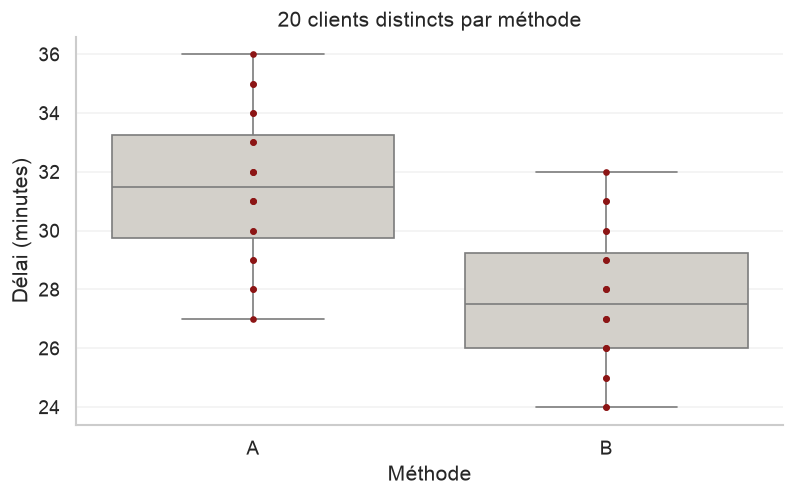

In [31]:
fig, ax = plt.subplots()
sns.boxplot(data=livraisons,x="methode",y="delai",color="#D5D0C8",ax=ax)
sns.stripplot(data=livraisons,x="methode",y="delai",jitter=False,color="#8C1515",size=4,ax=ax)
ax.set(title="20 clients distincts par méthode",xlabel="Méthode",ylabel="Délai (minutes)")
plt.show()

## 40. Un test de Welch : une question et des hypothèses

Hypothèse nulle $H_0$ : les moyennes des deux populations sont égales.
Le test compare la différence observée à sa variabilité estimée.



La **p-valeur** mesure, sous $H_0$ et les hypothèses du test, la probabilité d'un résultat au moins aussi extrême. Elle ne donne pas la probabilité que $H_0$ soit vraie.



`equal_var=False` choisit Welch sans imposer des variances égales.
On suppose les observations indépendantes et des distributions suffisamment proches de la normale ici, sans valeurs extrêmes dominantes.

## 41. Exercice : différence, intervalle et décision

`stats.ttest_ind(a, b, equal_var=False)` renvoie notamment `pvalue`.
`confidence_interval(confidence_level=0.95)` donne un intervalle pour la différence des moyennes A moins B.



- Calculer la différence et son intervalle à 95 %.

- L'intervalle contient-il zéro ? La p-valeur est-elle inférieure à 0,05 ?

- Le responsable exige au moins 5 minutes gagnées. Les données suffisent-elles à garantir ce gain ?

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [32]:
# Votre essai

## 42. Correction : un gain estimé avec son incertitude

L'intervalle décrit une différence de moyennes, pas les durées de 95 % des livraisons.
La méthode vise une couverture de 95 % sur des études répétées sous ses hypothèses.\par Différence : 3,85 min. IC à 95 % : [2,27 ; 5,43] min. p-valeur : environ $1{,}66\times10^{-5}$. Le gain de 5 min n’est pas établi.

In [33]:
test = stats.ttest_ind(a, b, equal_var=False)
intervalle = test.confidence_interval(confidence_level=0.95)
print(a.mean() - b.mean(), test.pvalue)
print(intervalle.low, intervalle.high)

3.8500000000000014 1.6638425609543277e-05
2.2694209215396577 5.430579078460346


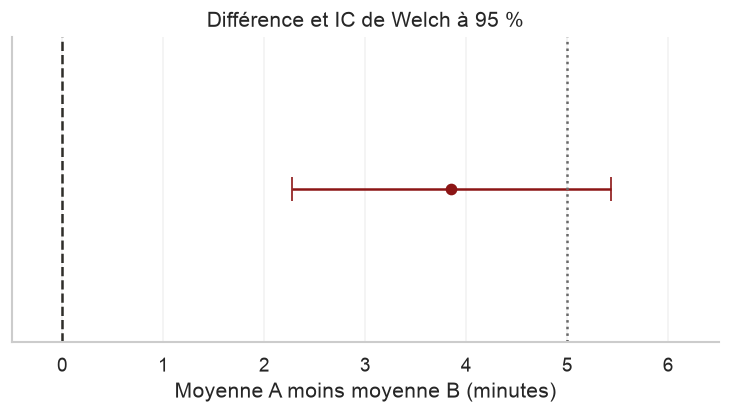

In [34]:
difference = a.mean()-b.mean()
fig, ax = plt.subplots(figsize=(7.6,3.3))
ax.errorbar(difference,0,xerr=[[difference-intervalle.low],[intervalle.high-difference]],fmt="o",capsize=7,color="#8C1515")
ax.axvline(0,ls="--",color="#2E2D29"); ax.axvline(5,ls=":",color="#686868")
ax.set(xlim=(-.5,6.5),yticks=[],xlabel="Moyenne A moins moyenne B (minutes)",title="Différence et IC de Welch à 95 %")
plt.show()

## 43. Corrélation : une relation à examiner

Le coefficient de Pearson est compris entre -1 et 1 lorsque les variances sont non nulles. Il mesure une relation linéaire.



Pour nos commandes, quantité et montant varient ensemble en partie parce que le montant utilise la quantité dans sa formule.



Un nuage de points permet de repérer cette relation, des groupes ou des valeurs inhabituelles. Une corrélation ne prouve pas, à elle seule, un effet causal.

In [35]:
correlations = ventes[["quantite", "net", "marge"]].corr()
print(correlations.round(2))

          quantite   net  marge
quantite      1.00  0.71   0.75
net           0.71  1.00   0.99
marge         0.75  0.99   1.00


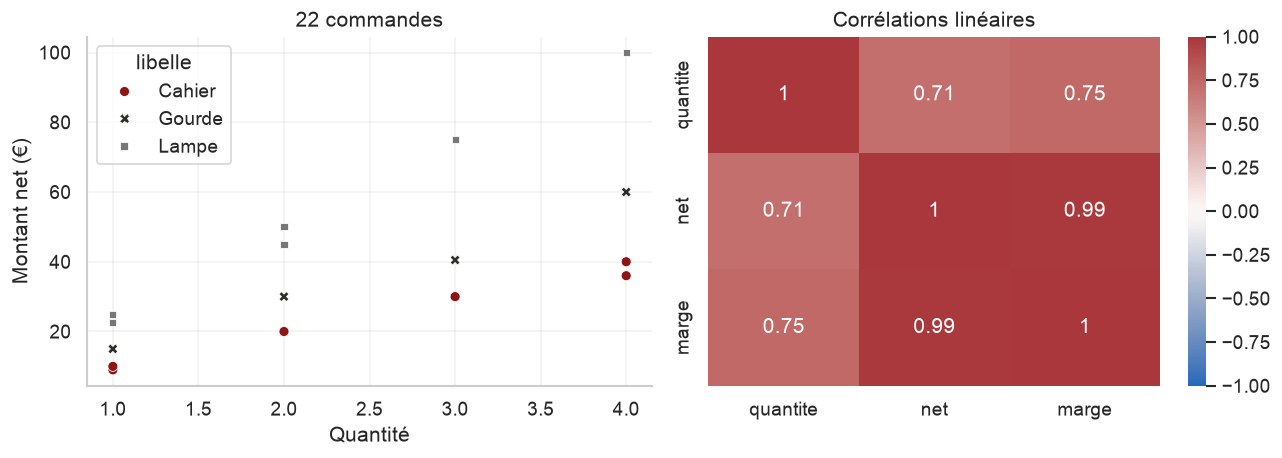

In [36]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
sns.scatterplot(data=ventes,x="quantite",y="net",hue="libelle",style="libelle",palette=["#8C1515","#2E2D29","#777777"],ax=axes[0])
axes[0].set(xlabel="Quantité",ylabel="Montant net (€)",title="22 commandes")
sns.heatmap(correlations,annot=True,vmin=-1,vmax=1,cmap="vlag",ax=axes[1])
axes[1].set_title("Corrélations linéaires")
plt.tight_layout(); plt.show()

## 44. Une même quantité peut produire plusieurs montants

Le nuage garde les produits visibles. Une formule et les prix expliquent une partie de la relation.

## 45. Prévoir la consommation électrique du lendemain

Un bâtiment dispose de 40 journées fictives. Avant chaque journée, il connaît la température prévue et ses heures d'ouverture prévues.



La consommation, en kWh, n'est connue qu'après la journée.
**Entrées :** température prévue et heures prévues.
**Sortie :** une estimation de la consommation quotidienne.



Une variable d'entrée porte aussi le nom de **caractéristique**. La grandeur à prévoir est la **cible**.

`parse_dates=["date"]` demande à `read_csv` de convertir cette colonne en dates.

In [37]:
energie = pd.read_csv(donnees / "energie_ch07.csv", sep=";",
                      parse_dates=["date"])
energie = energie.sort_values("date")
print(energie.head(3))

        date  temperature_prevue  heures_prevues  conso_kwh
0 2026-09-01               13.23             9.0     126.96
1 2026-09-02               18.41             9.0     114.03
2 2026-09-03               19.65             9.0     107.99


## 46. Séparer le passé et le futur avant l’ajustement

Fichiers bruts → données contrôlées → calculs → conclusion.
L'apprentissage ajuste les coefficients sur les 30 premières journées.
Le jeu de test garde les 10 journées suivantes pour mesurer l'erreur.



Une **fuite d'information** utilise, pendant la préparation ou l'ajustement, une information indisponible au moment de prévoir.

In [38]:
apprentissage = energie.iloc[:30].copy()
test_energie = energie.iloc[30:].copy()
colonnes = ["temperature_prevue", "heures_prevues"]

## 47. De la table pandas à la matrice NumPy

`to_numpy(dtype=float)` extrait les valeurs numériques dans l'ordre des colonnes choisi.



Le modèle linéaire est :
$$
\widehat y=b+w_T T+w_H H.
$$
Une colonne de 1 multiplie la constante $b$. Les deux autres portent $T$ et $H$.
`column_stack` assemble ces colonnes.

In [39]:
X_train = apprentissage[colonnes].to_numpy(dtype=float)
y_train = apprentissage["conso_kwh"].to_numpy(dtype=float)
M_train = np.column_stack([np.ones(len(X_train)), X_train])
print(M_train.shape, y_train.shape)

(30, 3) (30,)


## 48. SciPy ajuste, NumPy calcule les prédictions

`linalg.lstsq` minimise la somme des résidus au carré. Sa première sortie contient les trois coefficients.



Les coefficients changent seulement pendant l'apprentissage. Le test utilise la même transformation et les mêmes coefficients.

In [40]:
theta = linalg.lstsq(M_train, y_train)[0]
X_test = test_energie[colonnes].to_numpy(dtype=float)
M_test = np.column_stack([np.ones(len(X_test)), X_test])
predictions = M_test @ theta
print(theta.round(3))  # [115.290, -2.886, 5.419]

[115.29   -2.886   5.419]


## 49. Une référence simple pour juger l’erreur

L'erreur absolue moyenne, ou MAE, vaut :
$$
\operatorname{MAE}=\frac1n\sum_i |\widehat y_i-y_i|.
$$
Elle garde l'unité de la cible : ici le kWh.



La référence prédit toujours la moyenne **d'apprentissage**. Elle n'utilise aucune consommation du test pour calculer sa constante.

In [41]:
y_test = test_energie["conso_kwh"].to_numpy(dtype=float)
mae = np.abs(predictions - y_test).mean()
mae_reference = np.abs(y_train.mean() - y_test).mean()
print(round(mae, 2), round(mae_reference, 2))  # 2.73 et 12.85 kWh

2.73 12.85


## 50. Les erreurs se regardent aussi sur un graphique

La diagonale représente une prédiction exacte. Un point au-dessus correspond à une surestimation.
Une erreur moyenne faible peut cacher un sous-groupe mal prédit.

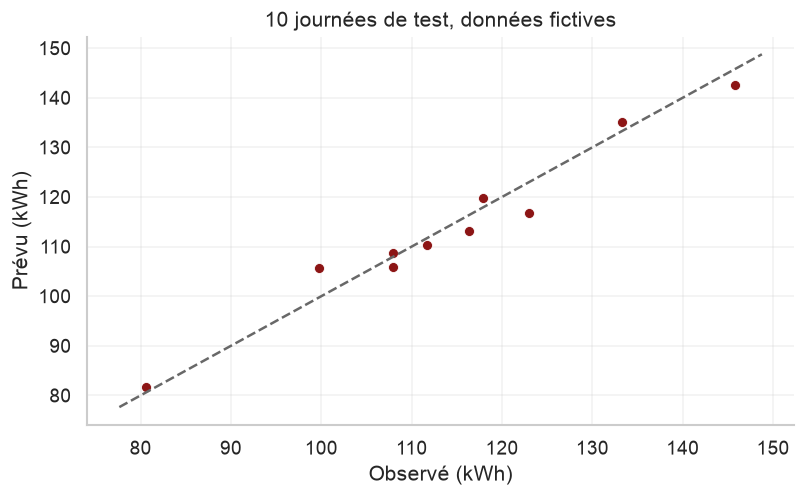

In [42]:
fig, ax = plt.subplots()
sns.scatterplot(x=y_test,y=predictions,color="#8C1515",ax=ax)
limites=[min(y_test.min(),predictions.min())-3,max(y_test.max(),predictions.max())+3]
ax.plot(limites,limites,ls="--",color="#686868")
ax.set(xlabel="Observé (kWh)",ylabel="Prévu (kWh)",title="10 journées de test, données fictives")
plt.show()

## 51. Débogage : préparer les données avant la séparation

On calcule la moyenne et l'écart-type sur les 40 journées, puis on découpe les données pour apprendre et tester.



- Pourquoi ce calcul utilise-t-il déjà des informations du futur ?

- Sur quelles lignes faut-il estimer les paramètres de standardisation ?

- Faut-il recalculer ces paramètres sur les dix journées de test ?


La cible du test doit aussi rester à l'écart de l'ajustement.

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [43]:
# Votre essai

## 52. Correction : une préparation que l’on réutilise

On conserve l'ordre des colonnes et les paramètres calculés sur l'apprentissage. Une colonne constante reçoit une échelle de 1 pour éviter une division par zéro.



Ces paramètres sont une partie du modèle à sauvegarder.

`sigma.where(condition, 1)` garde les valeurs où la condition est vraie et remplace les autres par 1.

In [44]:
mu = apprentissage[colonnes].mean()
sigma = apprentissage[colonnes].std(ddof=0)
echelle = sigma.where(sigma != 0, 1)
train_standardise = (apprentissage[colonnes] - mu) / echelle
test_standardise = (test_energie[colonnes] - mu) / echelle

## 53. Une catégorie peut devenir plusieurs colonnes

Un modèle numérique ne peut pas multiplier directement la chaîne « Lyon » par un poids.
`get_dummies` crée une colonne indicatrice par catégorie : 1 si elle est présente, 0 sinon.



Avec `reindex(columns=..., fill_value=0)`, le test reprend les colonnes de l'apprentissage. Une catégorie inconnue demande ensuite une règle explicite.

In [45]:
villes_train = pd.get_dummies(ventes[["ville"]], dtype=int)
villes_nouvelles = pd.DataFrame({"ville": ["Lyon", "Paris"]})
villes_test = pd.get_dummies(villes_nouvelles, dtype=int).reindex(
    columns=villes_train.columns, fill_value=0)
print(villes_test)

   ville_Lille  ville_Lyon  ville_Nantes
0            0           1             0
1            0           0             0


## 54. Une sortie réutilisable et un contrôle final

`to_csv(index=False)` écrit les colonnes sans ajouter l'index technique.



Exporter aussi les rejets et les définitions évite de perdre les décisions de nettoyage.
Les fichiers exportés par le notebook vont dans un dossier temporaire indiqué à l'écran.

In [46]:
ventes.to_csv(sorties / "ventes_propres.csv", index=False)
par_ville.to_csv(sorties / "resume_villes.csv", index=False)
rejets.to_csv(sorties / "rejets.csv", index=False)
sans_prix.to_csv(sorties / "references_inconnues.csv", index=False)
assert np.isclose(par_ville["ca"].sum(), ca)

## 55. Calculs vectorisés et lecture par lots

Pour les calculs déjà disponibles, préférer les opérations de colonnes, `groupby`, `merge` et les méthodes de chaînes à une boucle Python par ligne.



`apply` permet une fonction personnalisée, mais ne garantit pas une exécution vectorisée rapide.



Sur un gros fichier, `read_csv(..., chunksize=...)` lit des lots. Une somme se combine facilement entre lots. Une médiane exacte ou une déduplication globale demande davantage de suivi.

## 56. Mission : produire une courte analyse

Une direction reçoit les trois fichiers de commandes, produits et clients.



- Écrire les étapes de contrôle et annoncer les lignes retenues.

- Comparer les villes par chiffre d'affaires et panier moyen, avec les effectifs.

- Montrer un graphique de distribution et un graphique dans le temps.

- Rédiger deux observations chiffrées et une limite.


Chaque graphique doit répondre à une question. Le notebook laisse un espace pour votre analyse avant une proposition de correction.

**Votre démarche et vos vérifications**

Écrire les étapes, le résultat attendu et une limite.

In [47]:
# Votre essai

### Proposition de correction

Sur 26 lignes brutes, 22 commandes contribuent aux montants. Le CA net disponible est 838.00 €, la marge brute 309.00 € et le panier moyen 38.09 €. Les résumés par ville doivent retrouver le CA. Le 6 septembre représente zéro commande dans l'export complet. Une référence produit inconnue et deux commandes illisibles empêchent de valoriser tout le fichier. Les graphiques ci-dessus illustrent une comparaison par ville, la distribution des paniers et le temps.

## 57. Autoévaluation : expliquer avant de choisir la méthode

- Pourquoi vérifier les clés avant une jointure ?

- Quand `transform` convient-il mieux que `agg` ?

- Quand une absence dans le temps peut-elle devenir zéro ?

- Que mesure l'intervalle du test de Welch ?

- Quelle différence entre une variable disponible avant la prédiction et une information obtenue après ?


Les réponses argumentées figurent dans le notebook.

### Réponses

1. Des clés répétées peuvent multiplier les commandes et fausser les sommes.
2. `transform` reporte une statistique de groupe sur chaque ligne. `agg` réduit le groupe à un résumé.
3. Une absence devient zéro seulement si le contexte établit l’absence réelle d’activité, comme notre export complet du 6 septembre.
4. L’intervalle de Welch concerne la différence des moyennes de population A moins B, sous ses hypothèses.
5. Une information obtenue après la décision ne peut pas servir à prévoir comme si elle était connue avant. Cela créerait une fuite d’information.

## 58. Repères pour retrouver les méthodes

Besoin | Méthodes
--- | ---
Contrôler et convertir | info, isna, duplicated, to_numeric, to_datetime
Relier et empiler | merge, concat
Résumer et remettre en forme | groupby, agg, transform, pivot_table, melt
Travailler dans le temps | resample, rolling, shift
Visualiser | histplot, boxplot, scatterplot, heatmap
Estimer et prévoir | ttest_ind, linalg.lstsq, to_numpy

## Vérifications

Les contrôles relient les totaux aux commandes et les prévisions à des données qui ne servent pas à ajuster le modèle.

In [48]:
assert len(commandes)==26 and len(rejets)==2 and len(sans_prix)==1
assert ventes["id"].is_unique and len(ventes)==22
assert np.isclose(ventes["net"].sum(), par_ville["ca"].sum())
assert np.isclose(croise.to_numpy().sum(), ca)
assert journalier.loc["2026-09-06"]==0
assert moyenne_passee.iloc[:3].isna().all()
assert np.isclose(moyenne_passee.iloc[3],journalier.iloc[:3].mean())
assert apprentissage["date"].max()<test_energie["date"].min()
assert intervalle.low > 0 and intervalle.low < 5
assert mae < mae_reference
print("Contrôles de périmètre, de temps et de calcul réussis.")

Contrôles de périmètre, de temps et de calcul réussis.


## Compléments pour aller plus loin

- `astype("category")` mémorise des catégories et peut réduire la mémoire quand un texte se répète souvent. Mesurer avant de généraliser.
- `groupby(..., observed=True)` limite les groupes aux catégories observées. Une catégorie absente et une valeur manquante restent différentes.
- `groupby(..., dropna=False)` conserve un groupe pour les clés absentes.
- `pipe(fonction)` permet d'enchaîner des étapes lisibles. Chaque étape reçoit une table et renvoie une table.
- `read_csv(..., chunksize=...)` lit des lots. Les sommes partielles se combinent, mais une déduplication globale exige de mémoriser les clés déjà vues.
- Une boîte utilise la médiane et les quartiles, pas un intervalle de confiance. Une heatmap montre des coefficients, pas des preuves de causalité.

## Références officielles

- [Jointures et concaténation](https://pandas.pydata.org/docs/user_guide/merging.html)
- [Groupes et transformations](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [Dates et séries temporelles](https://pandas.pydata.org/docs/user_guide/timeseries.html)
- [Formats longs et tableaux croisés](https://pandas.pydata.org/docs/user_guide/reshaping.html)
- [Seaborn](https://seaborn.pydata.org/tutorial.html)
- [Test de Welch dans SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

Les jeux de données sont synthétiques et servent uniquement aux exemples de ce chapitre.